# Лабораторная работа №3. Транскрипция

**Цель работы:** Разработка модуля преобразования графем в фонемы (G2P) на русском языке, подготовка фонетической транскрипции для обучения моделей.

## 1. Предобработка данных

Для подготовки разметки использован `prepare_lexicon.py`. Скрипт обрабатывает файлы `.TextGrid` после MFA и формирует таблицы токенов и словарь произношений.


### 1.1. Обработка `spn` и пауз

Из разметки удалены целые предложения, содержащие `spn` (шум или ошибка выравнивания). Пустые интервалы преобразованы в токен `<SIL>`, который сохранён в полях `token` и `phones`.

После очистки осталось **19 619 предложений**. В данных с паузами сохранено **52 514** токенов `<SIL>`. Для файлов с паузами и без пауз использован один набор предложений.


In [1]:
import subprocess
import sys
import unicodedata
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from g2p import G2P, DEFAULT_RULES, load_tokens, build_lexicon, load_mfa_dictionary, phone_error_rate, word_accuracy


In [2]:
script_path = Path("prepare_lexicon.py")

result = subprocess.run(
    [sys.executable, str(script_path)],
    capture_output=True,
    text=True
)

print(result.stdout[-3000:])

if result.returncode != 0:
    print(result.stderr[-3000:])
    raise RuntimeError("Ошибка выполнения prepare_lexicon.py")

_align_v2/022150_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022151_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022152_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022153_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022154_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022155_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022156_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022157_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022158_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022159_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022160_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022161_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022162_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022163_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022164_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022165_RUSLAN.TextGrid', '../../data/RUSLAN_22050_align_v2/022166_RUSLAN.TextGrid', '../../data/RUSLAN_22

### 1.2. Полученные файлы

Скрипт создаёт `tokens_phones.csv` (без пауз), `tokens_phones_sil.csv` (с паузами) и `lexicon.csv` (словарь произношений по `train`). Также используется словарь Russian MFA v3.1.0.


In [3]:
tokens = pd.read_csv("data/tokens_phones.csv", sep="|")
tokens_sil = pd.read_csv("data/tokens_phones_sil.csv", sep="|")
lexicon = pd.read_csv("data/lexicon.csv", sep="|")

spn_count = tokens["phones"].fillna("").str.split().apply(
    lambda x: "spn" in x
).sum()

sil_count = (tokens_sil["token"] == "<SIL>").sum()

train = tokens[tokens["set"] == "train"]
test = tokens[tokens["set"] == "test"]

train_pairs = set(zip(train["token"], train["phones"]))
lexicon_pairs = set(zip(lexicon["word"], lexicon["phones"]))

results = pd.DataFrame({
    "Показатель": [
        "Предложений всего",
        "Предложений train",
        "Предложений test",
        "Токенов с spn",
        "Пауз <SIL>",
        "Записей в словаре",
        "Произношений словаря вне train",
    ],
    "Значение": [
        tokens["id"].nunique(),
        train["id"].nunique(),
        test["id"].nunique(),
        spn_count,
        sil_count,
        len(lexicon),
        len(lexicon_pairs - train_pairs),
    ],
})

display(results)

,Показатель,Значение
0,Предложений всего,19619
1,Предложений train,15667
2,Предложений test,3952
3,Токенов с spn,0
4,Пауз <SIL>,52514
5,Записей в словаре,39204
6,Произношений словаря вне train,0


### 1.3. Вывод

После очистки получено **19 619 предложений**: **15 667** в `train` и **3952** в `test`. Сохранены **52 514** пауз `<SIL>`. Обучающий словарь содержит **39 204** записи; произношений из тестовой части в него не добавлено. Данные готовы к анализу и обучению G2P.


## 2. Разведочный анализ фонемного инвентаря

На данном этапе проводится исследование фонетического состава корпуса RUSLAN на основе разметки Montreal Forced Aligner (MFA).

Анализ включает определение частот фонем, изучение редких фонем, оценку длительностей, исследование слов вне словаря (OOV), проверку омографов и сопоставление фонетического инвентаря с целевым набором.

### 2.1. Частотный анализ фонем

Первоначально определим количество уникальных фонем, представленных в корпусе, и частоту их появления. Для анализа используется файл `tokens_phones.csv`, полученный на этапе предобработки. Токены пауз `<SIL>` в подсчёте не учитываются.

Загружаем данные и считаем фонемы

In [4]:
# Загружаем предобработанные данные
tokens = pd.read_csv("data/tokens_phones.csv", sep="|")

# Собираем все фонемы корпуса
all_phones = []

for transcription in tokens["phones"].dropna():
    all_phones.extend(transcription.split())

# Подсчитываем частоты
phone_counts = Counter(all_phones)

phone_df = pd.DataFrame(
    phone_counts.items(),
    columns=["Фонема", "Частота"]
).sort_values("Частота", ascending=False).reset_index(drop=True)

phone_df["Доля, %"] = (
    phone_df["Частота"] / phone_df["Частота"].sum() * 100
)

print("Всего фонем:", len(all_phones))
print("Уникальных фонем:", len(phone_counts))

display(phone_df)

Всего фонем: 1238199
Уникальных фонем: 55


,Фонема,Частота,"Доля, %"
0,ɪ,100360,8.105321
1,ə,93840,7.578749
2,ɐ,65380,5.280250
3,a,55335,4.468991
4,t̪,54264,4.382494
5,j,48395,3.908499
6,n̪,48212,3.893720
7,e,43349,3.500972
8,s̪,41146,3.323052
9,r,39929,3.224764


Строим график частот

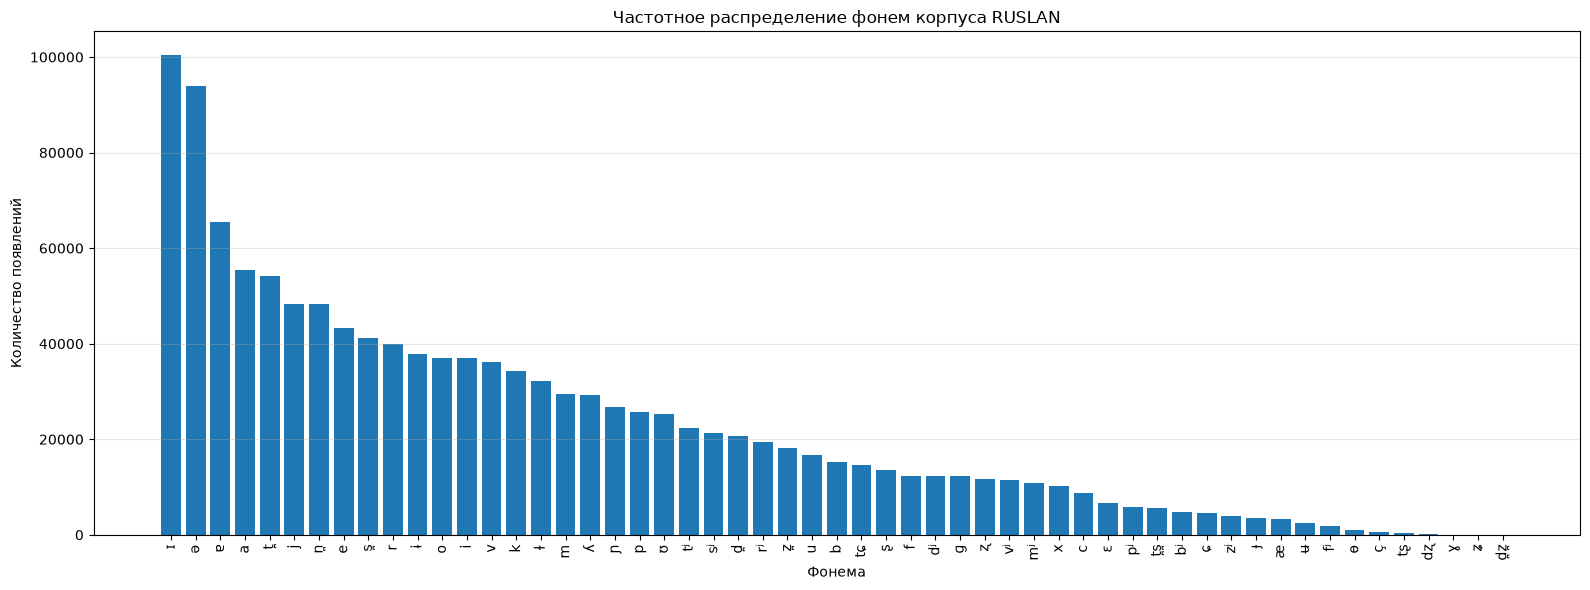

In [5]:
plt.figure(figsize=(16, 6))

plt.bar(
    phone_df["Фонема"],
    phone_df["Частота"]
)

plt.title("Частотное распределение фонем корпуса RUSLAN")
plt.xlabel("Фонема")
plt.ylabel("Количество появлений")

plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Проверяем инвентарь на служебные метки

In [6]:
print("Служебные метки:")

for special in ["spn", "<SIL>", "sil", ""]:
    print(f"{repr(special)}: {phone_counts.get(special, 0)}")

print("\nВсе уникальные фонемы:")
print(sorted(phone_counts.keys()))

Служебные метки:
'spn': 0
'<SIL>': 0
'sil': 0
'': 0

Все уникальные фонемы:
['a', 'b', 'bʲ', 'c', 'dʐ', 'dʲ', 'd̪', 'd̪z̪', 'e', 'f', 'fʲ', 'i', 'j', 'k', 'm', 'mʲ', 'n̪', 'o', 'p', 'pʲ', 'r', 'rʲ', 'sʲ', 's̪', 'tɕ', 'tʂ', 'tʲ', 't̪', 't̪s̪', 'u', 'v', 'vʲ', 'x', 'zʲ', 'z̪', 'æ', 'ç', 'ɐ', 'ɕ', 'ə', 'ɛ', 'ɟ', 'ɡ', 'ɣ', 'ɨ', 'ɪ', 'ɫ', 'ɲ', 'ɵ', 'ʂ', 'ʉ', 'ʊ', 'ʎ', 'ʐ', 'ʑ']


In [7]:
# Выделяем самые редкие фонемы
rare_phone_names = phone_df.nsmallest(6, "Частота")["Фонема"].tolist()

# Находим слова, содержащие эти фонемы
examples = []

for phone in rare_phone_names:
    matches = tokens[
        tokens["phones"].fillna("").str.split().apply(
            lambda x: phone in x
        )
    ]

    for _, row in matches.head(10).iterrows():
        examples.append({
            "Фонема": phone,
            "Слово": row["token"],
            "Транскрипция": row["phones"],
            "ID предложения": row["id"]
        })

rare_examples = pd.DataFrame(examples)

display(rare_examples)

,Фонема,Слово,Транскрипция,ID предложения
0,d̪z̪,зальцбурге,z̪ ɐ ʎ d̪z̪ b ʊ r ɟ e,010104_RUSLAN
1,ʑ,уезжал,ʊ j ɪ ʑ a ɫ,002126_RUSLAN
2,ʑ,приезжал,p rʲ ɪ j ɪ ʑ a ɫ,002775_RUSLAN
3,ʑ,уезжал,ʊ j ɪ ʑ a ɫ,002975_RUSLAN
4,ʑ,заезженную,z̪ ɐ j e ʑ ɪ n̪ ʊ j ʊ,003243_RUSLAN
5,ʑ,приезжал,p rʲ ɪ j ɪ ʑ a ɫ,003825_RUSLAN
6,ʑ,обожженный,ɐ b ɐ ʑ ɪ n̪ ɨ j,006411_RUSLAN
7,ʑ,прожженным,p r ɐ ʑ ɪ n̪ ɨ m,006529_RUSLAN
8,ʑ,выезжавший,v ɨ j ɪ ʑ a f ʂ ɨ j,009085_RUSLAN
9,ʑ,зажженными,z̪ ɐ ʑ ɪ n̪ ɨ mʲ ɪ,009258_RUSLAN


### Выводы по частотному анализу фонем

В результате анализа фонетической разметки корпуса RUSLAN было обнаружено **55 уникальных фонем**. Общее количество вхождений составляет приблизительно 1,24 млн.

Наиболее частотными оказались фонемы `ɪ` (100 360 вхождений, 8,11%), `ə` (93 840, 7,58%) и `ɐ` (65 380, 5,28%). Это согласуется с особенностями русского языка, в частности с редукцией гласных в безударных слогах.

Распределение фонем неравномерно. Наиболее редкими оказались `d̪z̪` (1 вхождение), `ʑ` (18), `ɣ` (23), `dʐ` (228), `tʂ` (280) и `ç` (496).

Анализ конкретных слов показал, что редкие фонемы часто имеют фонетическое объяснение:

- `d̪z̪` встретилась только в слове «зальцбурге», что может быть связано с особенностями транскрипции иностранного названия.
- `ʑ` встречается в словах «уезжал», «приезжал», «зажженной» и отражает особое произношение шипящих.
- `ɣ` наблюдается в словах «бухгалтер», «сверхсрочник» и связана с озвончением согласного «х».
- `dʐ` характерна для сочетания «дж» в словах «джинсы», «пиджак», «джон».
- `tʂ` встречается в словах «лучше», «худшие», «сумасшедший» и связана с особенностями произношения сочетаний согласных.
- `ç` наблюдается в словах «эпохи», «стихи», «психике» и отражает смягчённое произношение «х».

Таким образом, редкость фонем не обязательно свидетельствует об ошибках разметки. Большинство из них встречается в определённых фонетических контекстах, поэтому удалять их только из-за низкой частотности нецелесообразно. Решение об их сохранении или преобразовании следует принимать после сопоставления с целевым фонемным инвентарём.

Проверка служебных меток показала, что `spn`, `<SIL>` и `sil` отсутствуют в данных для обучения транскриптора, что подтверждает корректность выполненной предобработки.

## 3. Разработка G2P

В исходный `g2p.py` добавлена обработка слов по трём источникам: сначала словарь RUSLAN (`train`), затем Russian MFA, затем фонетические правила для оставшихся OOV-слов.

При нескольких вариантах MFA выбирается произношение с помощью фонемной биграммной модели, обученной на `train`. Для OOV используются смягчение и оглушение согласных, йотация, обработка сочетаний букв, окончаний и редукция гласных. Ударение приблизительно определяется по похожим словам из обучающего словаря.

Токен `<SIL>` передаётся без изменений.


### 3.1. Проверка работы модели

Сначала создаём словарь из обучающих данных, затем проверяем транскрипции слов из RUSLAN, MFA и остаточных OOV, а также сохранение `<SIL>`.


In [8]:
tokens = load_tokens()
train = tokens[tokens["set"] == "train"].copy()
test = tokens[tokens["set"] == "test"].copy()
lexicon = build_lexicon(train)
g2p = G2P(lexicon, rules={"mfa_variant_rerank": True})

print(f"Токенов train/test: {len(train)} / {len(test)}")
print(f"Слов RUSLAN: {len(lexicon)}")
print(f"Слов MFA: {len(g2p.mfa_dict)}")


dropping 0 tokens without a transcription (0.00%)
Токенов train/test: 175400 / 44162
Слов RUSLAN: 38561
Слов MFA: 452397


**Примеры транскрипций**


In [9]:
ruslan_words = list(lexicon)[:3]

mfa_words = [
    word for word in g2p.mfa_dict
    if word not in lexicon
][:3]

residual_words = [
    word for word in test["token"].unique()
    if word not in lexicon and word not in g2p.mfa_dict
][:3]

examples = (
    [(word, "RUSLAN") for word in ruslan_words]
    + [(word, "Russian MFA") for word in mfa_words]
    + [(word, "Фонетические правила") for word in residual_words]
)

rows = []

for word, source in examples:
    predicted = g2p.transcribe([word])[0]

    rows.append({
        "Слово": word,
        "Источник": source,
        "Предсказанная транскрипция": " ".join(predicted)
    })

display(pd.DataFrame(rows))

,Слово,Источник,Предсказанная транскрипция
0,кого,RUSLAN,k ɐ v o
1,интересуют,RUSLAN,ɪ ɲ tʲ ɪ rʲ ɪ s̪ u j ʊ t̪
2,признания,RUSLAN,p rʲ ɪ z̪ n̪ a ɲ e
3,a,Russian MFA,a
4,b,Russian MFA,b ɛ
5,bob,Russian MFA,b o p
6,клинициста,Фонетические правила,k ʎ ɪ ɲ ɪ t̪s̪ ɨ s̪ t̪ ə
7,квартуполномоченного,Фонетические правила,k v ə r t̪ ʊ p ə ɫ n̪ ə m ə tɕ ɪ n̪ o v ə
8,андрее,Фонетические правила,ɐ n̪ d̪ rʲ e j ɪ


**Проверка токена паузы**


In [10]:
sentence = ["я", "вышел", "<SIL>", "из", "дома"]

predictions = g2p.transcribe(sentence)

display(pd.DataFrame({
    "Токен": sentence,
    "Фонемы": [" ".join(phones) for phones in predictions]
}))

assert predictions[2] == ["<SIL>"]
assert len(predictions) == len(sentence)

,Токен,Фонемы
0,я,j a
1,вышел,v ɨ ʂ ɨ ɫ
2,<SIL>,<SIL>
3,из,i z̪
4,дома,d̪ o m ə


**Примеры остаточных OOV-слов**


In [11]:
residual = test[
    ~test["token"].isin(lexicon)
    & ~test["token"].isin(g2p.mfa_dict)
].copy()

sample = residual.head(15)

rows = []

for _, item in sample.iterrows():
    word = item["token"]
    reference = item["phones"].split()
    predicted = g2p.transcribe([word])[0]

    rows.append({
        "Слово": word,
        "Эталон": " ".join(reference),
        "Предсказание": " ".join(predicted),
        "Совпадение": reference == predicted
    })

display(pd.DataFrame(rows))

,Слово,Эталон,Предсказание,Совпадение
0,клинициста,c ʎ i ɲ ɪ t̪s̪ ɨ s̪ t̪ ə,k ʎ ɪ ɲ ɪ t̪s̪ ɨ s̪ t̪ ə,False
1,квартуполномоченного,k v ɐ r t̪ u p ə ɫ n̪ ɐ m o tɕ ɪ n̪ ə v ə,k v ə r t̪ ʊ p ə ɫ n̪ ə m ə tɕ ɪ n̪ o v ə,False
2,андрее,ɐ n̪ d̪ rʲ e j e,ɐ n̪ d̪ rʲ e j ɪ,False
3,шевиотовый,ʂ ɨ vʲ ɪ o t̪ ə v ɨ j,ʂ ɪ vʲ ɪ ɐ t̪ o v ɨ j,False
4,плачевнее,p ɫ ɐ tɕ e v ɲ ɪ j e,p ɫ ə tɕ ɪ v ɲ e j ɪ,False
5,окончившаяся,ɐ k o ɲ tɕ ɪ f ʂ ɐ j a t̪ s̪ ə,ɐ k ə n̪ tɕ ɪ f ʂ ɐ j a sʲ ɪ,False
6,недолгие,ɲ ɪ d̪ o ɫ ɟ ɪ ɪ,ɲ ɪ d̪ ɐ ɫ ɟ i j ɪ,False
7,скомкано,s̪ k o m k ə n̪ ə,s̪ k ɐ m k a n̪ ə,False
8,переправлен,pʲ ɪ rʲ ɪ p r a v ʎ ɪ n̪,pʲ ɪ rʲ ɪ p r a v ʎ ɪ n̪,True
9,многострадальная,m n̪ ə ɡ ə s̪ t̪ r ɐ d̪ a ʎ n̪ ə j ə,m n̪ ə ɡ ə s̪ t̪ r ɐ d̪ a ʎ n̪ ə j ɪ,False


### 3.2. Оценка качества

Используем PER: число ошибок фонем, делённое на число фонем в эталоне. Отдельно считаем качество на `test`, в том числе для слов вне обоих словарей. Общий PER считается по целым предложениям без `<SIL>`.


In [12]:
reference = [phones.split() for phones in test["phones"]]
hypothesis = [
    g2p.transcribe([word])[0]
    for word in test["token"]
]

ruslan_mask = test["token"].isin(lexicon).to_numpy()
mfa_mask = test["token"].isin(g2p.mfa_dict).to_numpy()

def evaluate_subset(mask):
    ref = [r for r, selected in zip(reference, mask) if selected]
    hyp = [h for h, selected in zip(hypothesis, mask) if selected]

    return {
        "Токенов": len(ref),
        "PER": phone_error_rate(ref, hyp),
        "Word accuracy": word_accuracy(ref, hyp)
    }

results = {
    "Все токены (без границ предложений)": evaluate_subset(
        [True] * len(test)
    ),
    "In-vocabulary": evaluate_subset(
        ruslan_mask
    ),
    "OOV": evaluate_subset(
        ~ruslan_mask
    ),
    "MFA-only": evaluate_subset(
        ~ruslan_mask & mfa_mask
    ),
    "Residual OOV": evaluate_subset(
        ~ruslan_mask & ~mfa_mask
    )
}

metrics_df = pd.DataFrame.from_dict(
    results,
    orient="index"
)

display(
    metrics_df.style.format({
        "PER": "{:.4f}",
        "Word accuracy": "{:.4f}"
    })
)

,Токенов,PER,Word accuracy
Все токены (без границ предложений),44162,0.0210,0.9265
In-vocabulary,38411,0.0103,0.9575
OOV,5751,0.0635,0.7194
MFA-only,4500,0.0210,0.8604
Residual OOV,1251,0.1980,0.2118


In [13]:
sentence_ref = []
sentence_hyp = []

for _, sentence in test.groupby("id", sort=False):
    sentence = sentence.sort_values("token_id")

    words = sentence["token"].tolist()
    predictions = g2p.transcribe(words)

    ref = [
        p
        for transcription in sentence["phones"]
        for p in transcription.split()
        if p != "<SIL>"
    ]

    hyp = [
        p
        for transcription in predictions
        for p in transcription
        if p != "<SIL>"
    ]

    sentence_ref.append(ref)
    sentence_hyp.append(hyp)

running_per = phone_error_rate(sentence_ref, sentence_hyp)
residual_per = results["Residual OOV"]["PER"]

criteria = pd.DataFrame([
    {
        "Критерий": "Running text PER",
        "Получено": running_per,
        "Порог": 0.025,
        "Выполнен": running_per <= 0.025
    },
    {
        "Критерий": "Residual OOV PER",
        "Получено": residual_per,
        "Порог": 0.20,
        "Выполнен": residual_per <= 0.20
    }
])

display(criteria)

print(
    "Оба критерия выполнены:",
    criteria["Выполнен"].all()
)

,Критерий,Получено,Порог,Выполнен
0,Running text PER,0.021040,0.025,True
1,Residual OOV PER,0.198019,0.200,True


Оба критерия выполнены: True


### 3.3. Вывод

На тестовой выборке итоговая версия модели достигла **Running text PER = 0.0210** и **Residual OOV PER = 0.1980**. Оба значения укладываются в пороги задания (0.025 и 0.20). При повторном запуске результаты следует сверить с таблицей выше.


## 4. Подготовка метаданных для работы №4


Нужно сформировать два файла: `metadata_phones_gt.csv` с эталонными фонемами и `metadata_phones.csv` с результатами G2P. В обоих случаях сохраняем `<SIL>`.


In [14]:
data_dir = Path("data")
source_path = data_dir / "tokens_phones_sil.csv"

tokens_sil = pd.read_csv(
    source_path,
    sep="|",
    keep_default_na=False
)

print("Столбцы:", tokens_sil.columns.tolist())
print("Количество токенов:", len(tokens_sil))
print("Количество предложений:", tokens_sil["id"].nunique())
print("Количество пауз:", (tokens_sil["token"] == "<SIL>").sum())

display(tokens_sil.head(15))

Столбцы: ['id', 'token_id', 'token', 'phones', 'set']
Количество токенов: 272076
Количество предложений: 19619
Количество пауз: 52514


,id,token_id,token,phones,set
0,000000_RUSLAN,0,с,s̪,test
1,000000_RUSLAN,1,тревожным,t̪ rʲ ɪ v o ʐ n̪ ɨ m,test
2,000000_RUSLAN,2,чувством,tɕ u s̪ t̪ v ə m,test
3,000000_RUSLAN,3,берусь,bʲ ɪ r u sʲ,test
4,000000_RUSLAN,4,я,j a,test
5,000000_RUSLAN,5,за,z̪ ə,test
6,000000_RUSLAN,6,перо,pʲ ɪ r o,test
7,000000_RUSLAN,7,<SIL>,<SIL>,test
8,000001_RUSLAN,0,кого,k ɐ v o,train
9,000001_RUSLAN,1,<SIL>,<SIL>,train


### 4.1. Эталонная разметка

Собираем слова и фонемы из `tokens_phones_sil.csv` по `id`, сохраняя порядок `token_id`.


In [15]:
tokens_sil = tokens_sil.sort_values(
    ["id", "token_id"],
    kind="stable"
).copy()

# Убедимся, что нет некорректных транскрипций
invalid = tokens_sil[
    tokens_sil["phones"].astype(str).str.split().map(
        lambda p: "spn" in p
    )
]

assert invalid.empty, "В исходных данных остались spn-токены"

# Паузы должны иметь собственную фонемную метку
sil_rows = tokens_sil["token"] == "<SIL>"

assert sil_rows.any(), "В файле нет <SIL>"
assert (
    tokens_sil.loc[sil_rows, "phones"] == "<SIL>"
).all(), "Проверь разметку фонем для <SIL>"

gt_rows = []

for sentence_id, group in tokens_sil.groupby("id", sort=False):
    words = group["token"].astype(str).tolist()
    phones = group["phones"].astype(str).tolist()

    normalized_text = " ".join(
        word for word in words if word != "<SIL>"
    )

    gt_rows.append({
        "id": sentence_id,
        "normalized_text": normalized_text,
        "phones": " ".join(phones)
    })

metadata_gt = pd.DataFrame(gt_rows)

gt_path = data_dir / "metadata_phones_gt.csv"

metadata_gt.to_csv(
    gt_path,
    sep="|",
    header=False,
    index=False
)

print("Сохранено:", gt_path)
print("Предложений:", len(metadata_gt))

display(metadata_gt.head())

Сохранено: data/metadata_phones_gt.csv
Предложений: 19619


,id,normalized_text,phones
0,000000_RUSLAN,с тревожным чувством берусь я за перо,s̪ t̪ rʲ ɪ v o ʐ n̪ ɨ m tɕ u s̪ t̪ v ə m bʲ ɪ ...
1,000001_RUSLAN,кого интересуют признания литературного неудач...,k ɐ v o <SIL> ɪ ɲ tʲ ɪ rʲ ɪ s̪ u j ʊ t̪ p rʲ ɪ...
2,000002_RUSLAN,что поучительного в его исповеди,ʂ t̪ o p ə ʊ tɕ i tʲ ɪ ʎ n̪ ə v ə f j ɪ v o <S...
3,000003_RUSLAN,да и жизнь моя лишена внешнего трагизма,d̪ a i ʐ ɨ zʲ ɲ m ɐ j a ʎ ɪ ʂ ɨ n̪ a v ɲ e ʂ ɲ...
4,000004_RUSLAN,я абсолютно здоров,j a ɐ p s̪ ɐ ʎ u t̪ n̪ ə z̪ d̪ ɐ r o f <SIL>


### 4.2. Предсказанная разметка

Для каждого предложения получаем фонемы через обученный `G2P`. Словарь RUSLAN строится только по `train`, а паузы остаются на месте.


In [16]:
pred_rows = []

for sentence_id, group in tokens_sil.groupby("id", sort=False):
    words = group["token"].astype(str).tolist()

    predicted = g2p.transcribe(words)

    assert len(predicted) == len(words)

    normalized_text = " ".join(
        word for word in words if word != "<SIL>"
    )

    phone_sequence = " ".join(
        phone
        for token_phones in predicted
        for phone in token_phones
    )

    pred_rows.append({
        "id": sentence_id,
        "normalized_text": normalized_text,
        "phones": phone_sequence
    })

metadata_pred = pd.DataFrame(pred_rows)

print("Предсказано предложений:", len(metadata_pred))
display(metadata_pred.head())


Предсказано предложений: 19619


,id,normalized_text,phones
0,000000_RUSLAN,с тревожным чувством берусь я за перо,s̪ t̪ rʲ ɪ v o ʐ n̪ ɨ m tɕ u s̪ t̪ v ə m bʲ ɪ ...
1,000001_RUSLAN,кого интересуют признания литературного неудач...,k ɐ v o <SIL> ɪ ɲ tʲ ɪ rʲ ɪ s̪ u j ʊ t̪ p rʲ ɪ...
2,000002_RUSLAN,что поучительного в его исповеди,ʂ t̪ o p ə ʊ tɕ i tʲ ɪ ʎ n̪ ə v ə v j ɪ v o <S...
3,000003_RUSLAN,да и жизнь моя лишена внешнего трагизма,d̪ a i ʐ ɨ zʲ ɲ m ɐ j a ʎ ɪ ʂ ɨ n̪ a v ɲ e ʂ ɲ...
4,000004_RUSLAN,я абсолютно здоров,j a ɐ p s̪ ɐ ʎ u t̪ n̪ ə z̪ d̪ ɐ r o f <SIL>


### 4.3. Проверка фонем и сохранение

В MFA встречаются долгие согласные с `ː`, которых нет в целевом наборе. Перед сохранением заменяем их краткими фонемами и проверяем результат.


In [17]:
# Путь относительно labs/lab3_g2p
phones_path = Path("../../common/phones_mfa.txt")

assert phones_path.exists(), f"Не найден файл: {phones_path}"

allowed_phones = {
    line.strip()
    for line in phones_path.read_text(encoding="utf-8").splitlines()
    if line.strip()
}

allowed_phones.add("<SIL>")

def normalize_phone(phone):
    if phone in allowed_phones:
        return phone

    if phone.endswith("ː"):
        short_phone = phone[:-1]

        if short_phone in allowed_phones:
            return short_phone

    raise ValueError(f"Неизвестная фонема: {phone}")


metadata_pred["phones"] = metadata_pred["phones"].map(
    lambda sequence: " ".join(
        normalize_phone(phone)
        for phone in sequence.split()
    )
)

def check_metadata(df, name):
    assert df["id"].is_unique
    assert df["phones"].notna().all()
    assert df["phones"].ne("").all()

    used_phones = {
        phone
        for sequence in df["phones"]
        for phone in sequence.split()
    }

    unknown = used_phones - allowed_phones

    print(f"{name}:")
    print("  Предложений:", len(df))
    print("  Уникальных фонем:", len(used_phones))
    print("  Неизвестные фонемы:", sorted(unknown))
    print(
        "  Предложений с <SIL>:",
        df["phones"].str.split().map(
            lambda seq: "<SIL>" in seq
        ).sum()
    )

    assert not unknown, f"Найдены фонемы вне инвентаря: {unknown}"

check_metadata(metadata_gt, "Ground Truth")
check_metadata(metadata_pred, "Predicted")

assert len(metadata_gt) == len(metadata_pred)
assert metadata_gt["id"].equals(metadata_pred["id"])
assert metadata_gt["normalized_text"].equals(
    metadata_pred["normalized_text"]
)

# Паузы должны находиться в одинаковых позициях между токенами.
# Проверяем количество пауз в каждом предложении.
gt_sil = metadata_gt["phones"].str.split().map(
    lambda p: p.count("<SIL>")
)
pred_sil = metadata_pred["phones"].str.split().map(
    lambda p: p.count("<SIL>")
)

assert gt_sil.equals(pred_sil), "Количество пауз не совпадает"

print("\nПроверки успешно пройдены.")
metadata_pred.to_csv(data_dir / "metadata_phones.csv", sep="|", header=False, index=False)
print("Сохранено:", data_dir / "metadata_phones.csv")


Ground Truth:
  Предложений: 19619
  Уникальных фонем: 56
  Неизвестные фонемы: []
  Предложений с <SIL>: 18256
Predicted:
  Предложений: 19619
  Уникальных фонем: 56
  Неизвестные фонемы: []
  Предложений с <SIL>: 18256

Проверки успешно пройдены.
Сохранено: data/metadata_phones.csv


### 4.4. Сравнение разметок

Сравниваем эталонные и предсказанные фонемы для одних и тех же предложений.


In [18]:
comparison = metadata_gt.merge(
    metadata_pred,
    on=["id", "normalized_text"],
    suffixes=("_gt", "_pred")
)

display(
    comparison[
        ["id", "normalized_text", "phones_gt", "phones_pred"]
    ].head(10)
)

print("Предложений:", len(comparison))
print(
    "Полностью совпавших транскрипций:",
    (comparison["phones_gt"] == comparison["phones_pred"]).sum()
)

,id,normalized_text,phones_gt,phones_pred
0,000000_RUSLAN,с тревожным чувством берусь я за перо,s̪ t̪ rʲ ɪ v o ʐ n̪ ɨ m tɕ u s̪ t̪ v ə m bʲ ɪ ...,s̪ t̪ rʲ ɪ v o ʐ n̪ ɨ m tɕ u s̪ t̪ v ə m bʲ ɪ ...
1,000001_RUSLAN,кого интересуют признания литературного неудач...,k ɐ v o <SIL> ɪ ɲ tʲ ɪ rʲ ɪ s̪ u j ʊ t̪ p rʲ ɪ...,k ɐ v o <SIL> ɪ ɲ tʲ ɪ rʲ ɪ s̪ u j ʊ t̪ p rʲ ɪ...
2,000002_RUSLAN,что поучительного в его исповеди,ʂ t̪ o p ə ʊ tɕ i tʲ ɪ ʎ n̪ ə v ə f j ɪ v o <S...,ʂ t̪ o p ə ʊ tɕ i tʲ ɪ ʎ n̪ ə v ə v j ɪ v o <S...
3,000003_RUSLAN,да и жизнь моя лишена внешнего трагизма,d̪ a i ʐ ɨ zʲ ɲ m ɐ j a ʎ ɪ ʂ ɨ n̪ a v ɲ e ʂ ɲ...,d̪ a i ʐ ɨ zʲ ɲ m ɐ j a ʎ ɪ ʂ ɨ n̪ a v ɲ e ʂ ɲ...
4,000004_RUSLAN,я абсолютно здоров,j a ɐ p s̪ ɐ ʎ u t̪ n̪ ə z̪ d̪ ɐ r o f <SIL>,j a ɐ p s̪ ɐ ʎ u t̪ n̪ ə z̪ d̪ ɐ r o f <SIL>
5,000005_RUSLAN,у меня есть любящая родня,u mʲ ɪ ɲ a j e sʲ tʲ ʎ ʉ bʲ æ ɕ æ j ə r ɐ dʲ ɲ a,u mʲ ɪ ɲ a j e sʲ tʲ ʎ ʉ bʲ æ ɕ æ j ə r ɐ dʲ ɲ a
6,000006_RUSLAN,мне всегда готовы предоставить работу которая ...,m ɲ e f sʲ ɪ ɡ d̪ a ɡ ɐ t̪ o v ɨ p rʲ ɪ d̪ ɐ s...,m ɲ e f sʲ ɪ ɡ d̪ a ɡ ɐ t̪ o v ɨ p rʲ ɪ d̪ ɐ s...
7,000007_RUSLAN,мало того я обладаю преимуществами,m a ɫ ə t̪ ɐ v o <SIL> j a ɐ b ɫ ɐ d̪ a j ʊ p ...,m a ɫ ə t̪ ɐ v o <SIL> j a ɐ b ɫ ɐ d̪ a j ʊ p ...
8,000008_RUSLAN,мне без труда удается располагать к себе людей,m ɲ e bʲ ɪ s̪ t̪ r ʊ d̪ a ʊ d̪ a j ɪ t̪ s̪ ə r...,m ɲ e bʲ ɪ s̪ t̪ r ʊ d̪ a ʊ d̪ a j ɪ t̪ s̪ ə r...
9,000009_RUSLAN,я совершил десятки поступков уголовно наказуем...,j a s̪ ə vʲ ɪ r ʂ ɨ ɫ dʲ ɪ sʲ a t̪ c ɪ p ɐ s̪ ...,j a s̪ ə vʲ ɪ r ʂ ɨ ɫ dʲ ɪ sʲ a t̪ c ɪ p ɐ s̪ ...


Предложений: 19619
Полностью совпавших транскрипций: 12772


### Вывод

Созданы файлы с эталонной и предсказанной разметкой для **19 619 предложений**. Паузы `<SIL>` сохранены. В предсказаниях долгие согласные приведены к целевому инвентарю. Большинство показанных транскрипций совпадает или отличается отдельными фонемами.
